# Fashion Deep Learning Recommendation Systems Solution 

Bu projede, Kaggle moda ürünleri veri setindeki (fashion-product-images-small) 44.441 ürün görselini kullanarak seçilen veya yüklenen bir ürüne görsel açıdan en çok benzeyen 5 ürünü öneren uçtan uca bir Derin Öğrenme Tabanlı Tavsiye Sistemi (Visual Recommender System) geliştireceğiz. 

### Proje Yol Haritası 

+ **Veri Seti & EDA:** [Kaggle - Fashion Product Images (Small)](https://www.kaggle.com/datasets/paramaggarwal/fashion-product-images-small) görsellerinin işletim sistemi uyumlu (/ standartlı) okunması ve styles.csv keşifçi veri analizi
+ **Transfer Learning:** Önceden eğitilmiş ResNet50 (imagenet) + GlobalMaxPool2D mimarisi ile her görselden 2048 boyutlu L2-normalize öznitelik vektörü çıkarımı
+ **Modelleme & Kayıt:** Özniteliklerin (Images_features.pkl), dosya yollarının (filenames.pkl), derin öğrenme modelinin (fashion_resnet50_model.keras) ve KNN (NearestNeighbors) modelinin (neighbors_model.pkl) kaydedilmesi
+ **MLOps (Streamlit & Hugging Face Spaces):** Hızlı katalog seçimi, bellek içi (in-memory) yeni görsel yükleme, doğru indeksleme ve otomatik `images.zip` çıkartma destekli app.py arayüzünün oluşturulması

### Yapılacaklar

+ Projeyi ve amacını (isteneni) anla
+ Veri setini indir: [Fashion Product Images (Small)](https://www.kaggle.com/datasets/paramaggarwal/fashion-product-images-small)
+ Görsel dosya yollarını (images/) ve ürün meta verilerini (styles.csv) oku (Import Data)
+ EDA yap (Keşifçi Veri Analizi)
+ Veri Görselleştirme yap (Data Visualization)
+ Önceden eğitilmiş ResNet50 + GlobalMaxPool2D derin öğrenme modelini kur
+ Görsellerden 2048 boyutlu öznitelik vektörlerini çıkar ve L2 normalizasyonu uygula (Feature Extraction)
+ Çıkarılan öznitelikleri (Images_features.pkl), dosya yollarını (filenames.pkl) ve modeli kaydet
+ NearestNeighbors modelini eğit
+ Örnek bir ürün görseli için en benzer 5 ürünü bul ve görselleştir
+ Benzer ürünleri öneren Streamlit (app.py) uygulamasını oluştur
+ Modeli ve uygulamayı Hugging Face Spaces platformuna yükle

In [1]:
%%capture
pip install tensorflow scikit-learn pandas matplotlib seaborn pillow tqdm streamlit huggingface_hub

In [2]:
import os
import pickle as pkl
import warnings
warnings.filterwarnings("ignore")

import numpy as np
from numpy.linalg import norm
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
from PIL import Image as PILImage
from IPython.display import Image

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import GlobalMaxPool2D
from tensorflow.keras.preprocessing import image
from tensorflow.keras.applications.resnet50 import ResNet50, preprocess_input
from sklearn.neighbors import NearestNeighbors

## Import Data - Veri Okuma 

In [3]:
# Windows ('\') ve Linux/Hugging Face ('/') uyumu için yolları '/' ile standartlaştırıp sıralıyoruz.
image_dir = "images"
filenames = [
    os.path.join(image_dir, file).replace("\\", "/")
    for file in sorted(os.listdir(image_dir))
    if file.lower().endswith((".jpg", ".jpeg", ".png"))
]
print("Toplam ürün görseli sayısı:", len(filenames))
filenames[:5]

Toplam ürün görseli sayısı: 44441


['images/10000.jpg',
 'images/10001.jpg',
 'images/10002.jpg',
 'images/10003.jpg',
 'images/10004.jpg']

## EDA & Data Visualization

In [4]:
if os.path.exists("styles.csv"):
    df = pd.read_csv("styles.csv", on_bad_lines = "skip")
    print("Tablo Boyutu:", df.shape)
    print("\nEksik Değerler:\n", df.isna().sum())
    display(df.head())

Tablo Boyutu: (44424, 10)

Eksik Değerler:
 id                      0
gender                  0
masterCategory          0
subCategory             0
articleType             0
baseColour             15
season                 21
year                    1
usage                 317
productDisplayName      7
dtype: int64


,id,gender,masterCategory,subCategory,articleType,baseColour,season,year,usage,productDisplayName
0,15970,Men,Apparel,Topwear,Shirts,Navy Blue,Fall,2011.0,Casual,Turtle Check Men Navy Blue Shirt
1,39386,Men,Apparel,Bottomwear,Jeans,Blue,Summer,2012.0,Casual,Peter England Men Party Blue Jeans
2,59263,Women,Accessories,Watches,Watches,Silver,Winter,2016.0,Casual,Titan Women Silver Watch
3,21379,Men,Apparel,Bottomwear,Track Pants,Black,Fall,2011.0,Casual,Manchester United Men Solid Black Track Pants
4,53759,Men,Apparel,Topwear,Tshirts,Grey,Summer,2012.0,Casual,Puma Men Grey T-shirt


In [5]:
sample_pil = PILImage.open(filenames[0])
print("Örnek Görsel Boyutu:", sample_pil.size, "| Renk Modu:", sample_pil.mode)

Örnek Görsel Boyutu: (60, 80) | Renk Modu: RGB


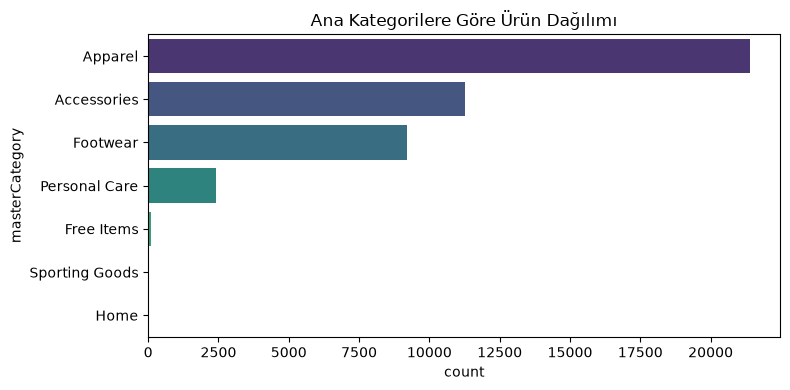

In [6]:
if os.path.exists("styles.csv"):
    plt.figure(figsize = (8, 4))
    sns.countplot(y = df["masterCategory"], order = df["masterCategory"].value_counts().index, palette = "viridis")
    plt.title("Ana Kategorilere Göre Ürün Dağılımı")
    plt.tight_layout()
    plt.show()

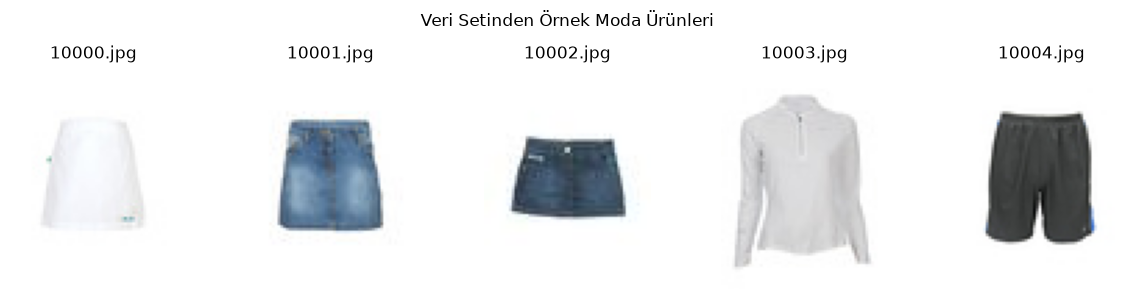

In [7]:
plt.figure(figsize = (12, 3))
for i in range(5):
    plt.subplot(1, 5, i + 1)
    plt.imshow(PILImage.open(filenames[i]))
    plt.title(os.path.basename(filenames[i]))
    plt.axis("off")
plt.suptitle("Veri Setinden Örnek Moda Ürünleri")
plt.tight_layout()
plt.show()

## ResNet50 Transfer Learning Modelinin Kurulumu

In [8]:
base_model = ResNet50(weights = "imagenet", include_top = False, input_shape = (224, 224, 3))
base_model.trainable = False  # Önceden eğitilmiş ImageNet ağırlıklarını dondur

model = Sequential([
    base_model,
    GlobalMaxPool2D()
])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ resnet50 (Functional)                │ (None, 7, 7, 2048)          │      23,587,712 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_max_pooling2d                 │ (None, 2048)                │               0 │
│ (GlobalMaxPooling2D)                 │                             │                 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 23,587,712 (89.98 MB)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 23,587,712 (89.98 MB)

## Görsellerden Öznitelik Çıkarımı - Feature Extraction 

In [9]:
def extract_features_from_images(image_path, model):
    img = image.load_img(image_path, target_size = (224, 224))
    img_array = image.img_to_array(img)
    img_expand_dim = np.expand_dims(img_array, axis = 0)
    img_preprocess = preprocess_input(img_expand_dim)
    result = model.predict(img_preprocess, verbose = 0).flatten()
    norm_result = result / norm(result)
    return norm_result

In [10]:
first_feature = extract_features_from_images(filenames[0], model)
print("Tek görsel öznitelik vektör boyutu:", first_feature.shape)
first_feature[:10]

Tek görsel öznitelik vektör boyutu: (2048,)


array([0.        , 0.01761619, 0.00171604, 0.00808791, 0.0258895 ,
       0.01252665, 0.01442038, 0.01690411, 0.00714538, 0.00018291],
      dtype=float32)

In [11]:
# GPU kontrolü (Varsa TensorFlow otomatik kullanır, yoksa CPU'da tüm çekirdekleri paralel çalıştırır)
print("Aktif GPU:", tf.config.list_physical_devices("GPU"))

# Hızlı ve paralel öznitelik çıkarımı (tf.data + Batch Prediction)
BATCH_SIZE = 64  # VRAM / RAM durumuna göre 128 de yapabilirsiniz

def load_and_preprocess(path):
    img = tf.io.read_file(path)
    img = tf.image.decode_jpeg(img, channels = 3)
    img = tf.image.resize(img, [224, 224])
    return preprocess_input(img)

# Görselleri arka planda paralel oku ve 64'lü paketler halinde hazırla
ds = tf.data.Dataset.from_tensor_slices(filenames)
ds = ds.map(load_and_preprocess, num_parallel_calls = tf.data.AUTOTUNE)
ds = ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

# 44.441 tekil çağrı yerine tek seferde toplu tahmin (~695 adım) ve vektörize L2 normalizasyon
raw_features = model.predict(ds, verbose = 1)
image_features = list(raw_features / norm(raw_features, axis = 1, keepdims = True))

Aktif GPU: []
695/695 ━━━━━━━━━━━━━━━━━━━━ 1014s 1s/step


## Özniteliklerin ve Modellerin Kaydedilmesi / Yüklenmesi

In [12]:
pkl.dump(image_features, open("Images_features.pkl", "wb"))
pkl.dump(filenames, open("filenames.pkl", "wb"))
model.save("fashion_resnet50_model.keras")

In [13]:
Image_features = pkl.load(open("Images_features.pkl", "rb"))
filenames = pkl.load(open("filenames.pkl", "rb"))
np.array(Image_features).shape

(44441, 2048)

## KNN (NearestNeighbors) ile Benzer Ürün Öneri Modeli 

In [14]:
neighbors = NearestNeighbors(n_neighbors = 6, algorithm = "brute", metric = "euclidean")
neighbors.fit(Image_features)
pkl.dump(neighbors, open("neighbors_model.pkl", "wb"))

In [15]:
query_img = "images/16871.jpg" if os.path.exists("images/16871.jpg") else filenames[0]
input_image = extract_features_from_images(query_img, model)

distances, indices = neighbors.kneighbors([input_image])
print("Önerilen Ürün İndeksleri:", indices[0])
print("Öklid Mesafeleri:", np.round(distances[0], 4))

Önerilen Ürün İndeksleri: [ 5828 23452 16987 16986 16494 15676]
Öklid Mesafeleri: [0.6186 0.6214 0.6269 0.6318 0.636  0.6411]


## Seçilen Ürün ve En Benzer 5 Ürünün Görselleştirilmesi 

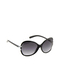

In [16]:
Image(query_img)

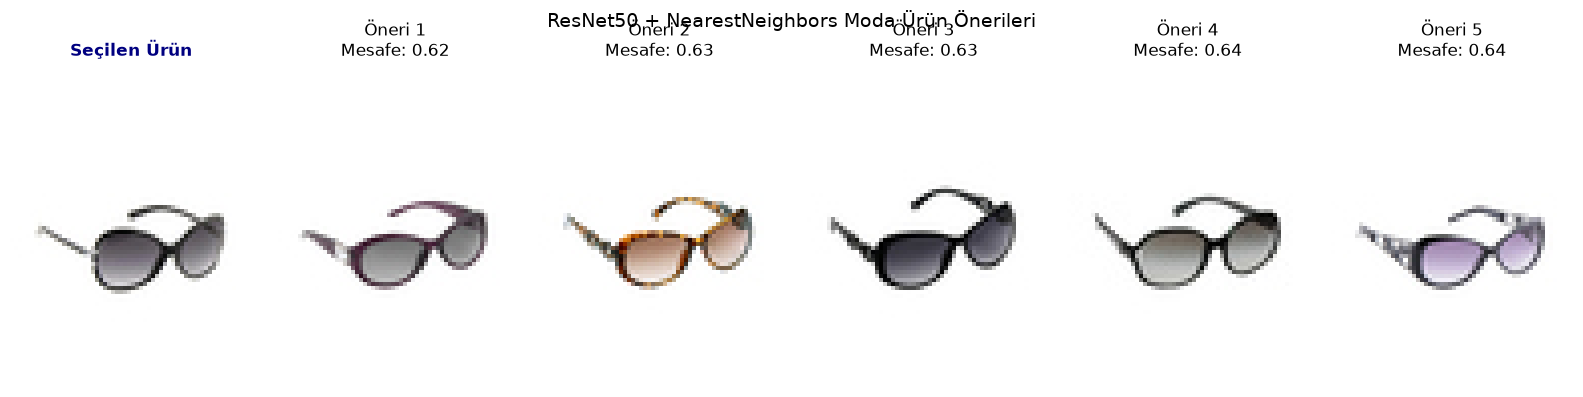

In [17]:
plt.figure(figsize = (16, 4))

plt.subplot(1, 6, 1)
plt.imshow(PILImage.open(query_img))
plt.title("Seçilen Ürün", fontweight = "bold", color = "navy")
plt.axis("off")

for i in range(1, 6):
    plt.subplot(1, 6, i + 1)
    rec_path = filenames[indices[0][i]]
    plt.imshow(PILImage.open(rec_path))
    plt.title(f"Öneri {i}\nMesafe: {distances[0][i]:.2f}")
    plt.axis("off")

plt.suptitle("ResNet50 + NearestNeighbors Moda Ürün Önerileri", fontsize = 14)
plt.tight_layout()
plt.show()

## MLOps: Streamlit Web Uygulaması (app.py)  

Aşağıdaki hücreler çalıştırıldığında her iki yaklaşımın en güçlü yönlerini birleştiren app.py oluşturulur:
+ **Platform Bağımsız Yol & images.zip Desteği:** Hugging Face Spaces'teki 10.000 dosya sınırına takılmamak için yüklenen images.zip arşivini ilk açılışta otomatik çıkartır ve dosya yollarını / formatına dönüştürür.
+ **Hızlı Arayüz & Bellek İçi (In-Memory) İşleme:** Katalog seçiminde arayüzün kilitlenmemesi için ilk 1.000 ürünü listeler; yeni görsel yüklendiğinde diske geçici dosya yazmadan doğrudan PIL üzerinden öznitelik çıkarır.
+ **Akıllı İndeksleme (`distances[0][0] < 1e-4`):** Katalogdaki ürünlerde kendisini (index 0) atlayıp 1-5 arası ürünleri önerir; dışarıdan yüklenen yeni görsellerde ise en yakın eşleşmeyi (index 0) kaybetmeden ilk 5 ürünü önerir.

In [18]:
%%writefile app.py
import os
import zipfile
import pickle as pkl
import numpy as np
from numpy.linalg import norm
from PIL import Image
import streamlit as st
from huggingface_hub import hf_hub_download
from tensorflow.keras.models import Sequential, load_model
from tensorflow.keras.layers import GlobalMaxPool2D
from tensorflow.keras.preprocessing import image
from tensorflow.keras.applications.resnet50 import ResNet50, preprocess_input
from sklearn.neighbors import NearestNeighbors

st.set_page_config(page_title = "Fashion Recommender System", page_icon="👗", layout = "wide")
st.title("👗 Fashion Deep Learning Recommendation System")
st.write("Katalogdan bir ürün seçin veya yeni bir görsel yükleyin; **ResNet50 + NearestNeighbors** modeli en benzer 5 ürünü önersin.")

REPO_ID = "Anl08By/fashion-recommender-system"

@st.cache_resource
def load_resources():
    # Dosyalar yerelde yoksa (ör. Streamlit Cloud'da) Hugging Face Model Hub'dan ücretsiz indir
    for fname in ["Images_features.pkl", "filenames.pkl", "neighbors_model.pkl", "images.zip"]:
        if not os.path.exists(fname):
            hf_hub_download(repo_id=REPO_ID, filename=fname, repo_type="model", local_dir=".")

    if not os.path.exists("images") and os.path.exists("images.zip"):
        with zipfile.ZipFile("images.zip", "r") as z:
            z.extractall(".")

    features = np.array(pkl.load(open("Images_features.pkl", "rb")))
    files = [f.replace("\\", "/") for f in pkl.load(open("filenames.pkl", "rb"))]

    if os.path.exists("fashion_resnet50_model.keras"):
        cnn_model = load_model("fashion_resnet50_model.keras")
    else:
        base_model = ResNet50(weights = "imagenet", include_top = False, input_shape = (224, 224, 3))
        base_model.trainable = False
        cnn_model = Sequential([base_model, GlobalMaxPool2D()])

    if os.path.exists("neighbors_model.pkl"):
        knn = pkl.load(open("neighbors_model.pkl", "rb"))
    else:
        knn = NearestNeighbors(n_neighbors = 6, algorithm = "brute", metric = "euclidean")
        knn.fit(features)

    return cnn_model, knn, files, features

def extract_features_pil(img_pil, cnn_model):
    img_resized = img_pil.convert("RGB").resize((224, 224))
    img_array = image.img_to_array(img_resized)
    img_expand = np.expand_dims(img_array, axis = 0)
    result = cnn_model.predict(preprocess_input(img_expand), verbose = 0).flatten()
    return result / norm(result)

model, neighbors, filenames, Image_features = load_resources()

tab1, tab2 = st.tabs(["📂 Katalogdan Ürün Seç", "📤 Yeni Görsel Yükle"])

with tab1:
    selected_file = st.selectbox("Katalogdan bir ürün seçin (İlk 1.000 ürün):", filenames[:1000])
    if st.button("Benzer Ürünleri Öner", key = "btn_catalog"):
        idx = filenames.index(selected_file)
        distances, indices = neighbors.kneighbors([Image_features[idx]])

        if os.path.exists(selected_file):
            st.subheader("Seçilen Ürün")
            st.image(selected_file, width = 200)

        st.subheader("Önerilen En Benzer 5 Ürün")
        cols = st.columns(5)
        for i, col in enumerate(cols, start = 1):
            rec_path = filenames[indices[0][i]]
            with col:
                if os.path.exists(rec_path):
                    st.image(rec_path, use_container_width = True)
                st.caption(f"{os.path.basename(rec_path)} (Mesafe: {distances[0][i]:.2f})")

with tab2:
    uploaded_file = st.file_uploader("Bir moda ürünü görseli yükleyin (.jpg, .jpeg, .png):", type=["jpg", "jpeg", "png"])
    if uploaded_file is not None:
        query_pil = Image.open(uploaded_file)
        st.subheader("Yüklenen Ürün")
        st.image(query_pil, width = 200)

        input_vec = extract_features_pil(query_pil, model)
        distances, indices = neighbors.kneighbors([input_vec])
        start = 1 if distances[0][0] < 1e-4 else 0

        st.subheader("Önerilen En Benzer 5 Ürün")
        cols = st.columns(5)
        for i, col in enumerate(cols):
            rec_idx = indices[0][start + i]
            rec_path = filenames[rec_idx]
            rec_dist = distances[0][start + i]
            with col:
                if os.path.exists(rec_path):
                    st.image(rec_path, use_container_width=True)
                st.caption(f"{os.path.basename(rec_path)} (Mesafe: {rec_dist:.2f})")

Writing app.py


## requirements.txt 

In [19]:
%%writefile requirements.txt
streamlit
tensorflow-cpu
scikit-learn
numpy
Pillow
huggingface_hub

Writing requirements.txt


## Hugging Face Spaces'e Yükleme ve Canlıya Alma 

In [ ]:
import os
import shutil
from huggingface_hub import HfApi

# 1. images/ klasörünü otomatik olarak images.zip haline getir (yoksa oluşturur)
if not os.path.exists("images.zip"):
    print("images.zip oluşturuluyor, lütfen bekleyin...")
    shutil.make_archive("images_archive", "zip", root_dir = ".", base_dir = "images")
    os.rename("images_archive.zip", "images.zip")

# 2. Hugging Face Model Hub'a ÜCRETSİZ otomatik yükleme
api = HfApi(token="HF_TOKEN_BURAYA")
repo_id = "Anl08By/fashion-recommender-system"

api.create_repo(repo_id = repo_id, repo_type = "model", exist_ok = True)

upload_list = [
    "app.py",
    "requirements.txt",
    "Images_features.pkl",
    "filenames.pkl",
    "neighbors_model.pkl",
    "fashion_resnet50_model.keras",
    "images.zip"
]

for f in upload_list:
    if os.path.exists(f):
        print(f"Yükleniyor: {f} ...")
        api.upload_file(path_or_fileobj = f, path_in_repo = f, repo_id = repo_id, repo_type = "model")

print(f"✅ Hugging Face Model Linkiniz: https://huggingface.co/{repo_id}")

images.zip oluşturuluyor, lütfen bekleyin...
Yükleniyor: app.py ...
Yükleniyor: requirements.txt ...
Yükleniyor: Images_features.pkl ...


Processing Files (0 / 0): |          |  0.00B /  0.00B            

New Data Upload: |          |  0.00B /  0.00B            

Yükleniyor: filenames.pkl ...


Processing Files (0 / 0): |          |  0.00B /  0.00B            

New Data Upload: |          |  0.00B /  0.00B            

... (2 outputs left out)

New Data Upload: |          |  0.00B /  0.00B            

Yükleniyor: fashion_resnet50_model.keras ...


Processing Files (0 / 0): |          |  0.00B /  0.00B            

New Data Upload: |          |  0.00B /  0.00B            

## README.md 

In [1]:
%%writefile README.md
# 👗 Fashion Deep Learning Recommendation System
### Moda Ürünleri İçin Görsel Tabanlı Derin Öğrenme Tavsiye Sistemi

[![Python](https://img.shields.io/badge/Python-3.11+-blue.svg)](https://www.python.org/)
[![TensorFlow](https://img.shields.io/badge/TensorFlow-ResNet50-FF6F00.svg)](https://www.tensorflow.org/)
[![Scikit-Learn](https://img.shields.io/badge/Scikit--Learn-KNN-F7931E.svg)](https://scikit-learn.org/)
[![Streamlit](https://img.shields.io/badge/Streamlit-Web_App-FF4B4B.svg)](https://streamlit.io/)
[![Hugging Face](https://img.shields.io/badge/Hugging_Face-Model_Hub-FFD21E.svg)](https://huggingface.co/)

🔗 **Canlı Uygulama (Streamlit Cloud):** `https://BURAYA-STREAMLIT-LINKINIZI-YAZIN.streamlit.app`  
🤗 **Hugging Face Model Deposu:** `https://huggingface.co/Anl08By/fashion-recommender-system`  
📊 **Veri Seti:** [Kaggle - Fashion Product Images (Small)](https://www.kaggle.com/datasets/paramaggarwal/fashion-product-images-small)

---

## 📌 Proje Özeti (Overview)

Bu proje, e-ticaret ve moda platformlarında kullanılan **Görsel Tabanlı Tavsiye Sistemi (Visual Recommender System)** mimarisini uçtan uca uygular. Veri setindeki **44.441** moda ürünü görselinden **Transfer Learning (ResNet50)** ile 2048 boyutlu öznitelik vektörleri (embeddings) çıkarılmış ve **K-En Yakın Komşu (`NearestNeighbors`)** algoritması kullanılarak seçilen veya dışarıdan yüklenen bir ürüne görsel açıdan en çok benzeyen **5 ürünün** önerilmesi sağlanmıştır.

> **🇬🇧 English Summary:** An end-to-end visual fashion recommendation engine built on 44,441 product images. Feature embeddings (2048-D, L2-normalized) are extracted via a frozen ImageNet-pretrained **ResNet50 + GlobalMaxPool2D** architecture and indexed with **Scikit-Learn `NearestNeighbors`** (Euclidean distance). Model artifacts are hosted on **Hugging Face Hub**, and the interactive web UI is deployed via **Streamlit**.

---

## 🧠 Sistem Mimarisi ve Teknik Özellikler

1. **Veri Ön İşleme & EDA:**
   * Görseller `224x224x3` boyutuna ölçeklendirilip ResNet50 `preprocess_input` dönüşümünden geçirilir.
   * Windows ve Linux sunucuları arasında tam uyumluluk için tüm dosya yolları `/` standardına dönüştürülmüştür.
2. **Derin Öğrenme ile Öznitelik Çıkarımı (Feature Extraction):**
   * `ResNet50(weights = "imagenet", include_top = False, input_shape = (224, 224, 3))` temel modelinin ağırlıkları dondurulmuş (`trainable = False`) ve sonuna `GlobalMaxPool2D` katmanı eklenmiştir.
   * Çıkarılan `2048` boyutlu vektörlere **L2 Normalizasyonu** uygulanarak `(44441, 2048)` boyutlu öznitelik matrisi oluşturulmuştur.
3. **Benzerlik Modeli (`NearestNeighbors`):**
   * `NearestNeighbors(n_neighbors = 6, algorithm = "brute", metric = "euclidean")` yapılandırması ile Öklid mesafesine göre en yakın komşular hesaplanır.
   * Katalog seçimlerinde ürünün kendisi (`index 0`) otomatik atlanırken, dışarıdan yüklenen yeni görsellerde `distances[0][0] < 1e-4` kontrolü ile en yakın eşleşme korunur.
4. **Bulut Entegrasyonu (MLOps):**
   * GitHub dosya boyutu sınırlarına takılmamak için büyük model çıktıları (`Images_features.pkl`, `filenames.pkl`, `neighbors_model.pkl`, `images.zip`) **Hugging Face Model Hub** üzerinde barındırılır ve `app.py` ilk çalıştığında `hf_hub_download` ile otomatik olarak çekilir.

---

## 📂 Proje Klasör Yapısı

```text
├── app.py                              # Streamlit web arayüzü ve Hugging Face Hub entegrasyonu
├── requirements.txt                    # Canlı ortam Python bağımlılıkları
├── Fashion_Recommender_Solution-v2.ipynb # Eğitim, EDA, öznitelik çıkarımı ve MLOps Notebook'u
└── README.md                           # Proje dokümantasyonu
```
*(Not: `Images_features.pkl`, `filenames.pkl`, `neighbors_model.pkl`, `fashion_resnet50_model.keras` ve `images.zip` dosyaları boyutları nedeniyle doğrudan Hugging Face Model Hub deposunda barındırılmaktadır.)*

---

## 🚀 Yerelde Kurulum ve Çalıştırma (Local Setup)

Projeyi kendi bilgisayarınızda çalıştırmak için aşağıdaki adımları izleyin:

```bash
# 1. Depoyu klonlayın
git clone [https://github.com/ANIL08BY/REPO-ADINIZ.git](https://github.com/ANIL08BY/REPO-ADINIZ.git)
cd REPO-ADINIZ

# 2. Sanal ortam oluşturun ve aktif edin
python -m venv venv
# Windows için:
venv\Scripts\activate
# Linux / macOS için:
source venv/bin/activate

# 3. Gerekli kütüphaneleri yükleyin
pip install -r requirements.txt

# 4. Streamlit uygulamasını başlatın
streamlit run app.py
```
*Uygulama ilk kez çalıştığında gerekli `.pkl` dosyalarını ve `images.zip` arşivini Hugging Face üzerinden otomatik indirip çalışma dizinine çıkartacaktır.*

---

## 🛠️ Kullanılan Teknolojiler

* **Derin Öğrenme & Makine Öğrenmesi:** TensorFlow / Keras (`ResNet50`, `GlobalMaxPool2D`), Scikit-Learn (`NearestNeighbors`), NumPy
* **Veri Analizi & Görselleştirme:** Pandas, Matplotlib, Seaborn, Pillow (PIL)
* **Arayüz & Canlıya Alma (MLOps):** Streamlit, Hugging Face Hub (`huggingface_hub`)

---

## 👤 Geliştirici

**Anıl Bilgehan Yüzgeç**  
* GitHub: [@ANIL08BY](https://github.com/ANIL08BY)

Writing README.md


## .gitignore 

In [2]:
%%writefile .gitignore
images/
myntradataset/
archive/
*.zip
styles.csv
*.pkl
*.keras
*.h5
uploaded_temp.jpg
__pycache__/
*.py[cod]
venv/
.venv/
env/
.env
.streamlit/secrets.toml
.ipynb_checkpoints/
.vscode/
Thumbs.db
Desktop.ini
.DS_Store

Writing .gitignore


# Sonuç 

+ Kaggle fashion-product-images-small veri setindeki 44.441 moda ürünü görseli üzerinde hem styles.csv tabanlı EDA yaptık hem de görsel benzerliğe dayalı Derin Öğrenme Tavsiye Sistemi geliştirdik.
+ Dosya yollarını Windows ve Linux (Hugging Face) ortamlarında sorunsuz çalışacak şekilde / ayırıcıyla standartlaştırdık.
+ Transfer Learning aşamasında ImageNet ağırlıklı ResNet50 (include_top=False, trainable=False) ve GlobalMaxPool2D katmanlarını birleştirerek her görseli 2048 boyutlu L2-normalize öznitelik vektörüne dönüştürdük.
+ Öznitelik matrisini (Images_features.pkl), dosya yollarını (filenames.pkl), Keras modelini (fashion_resnet50_model.keras) ve NearestNeighbors(n_neighbors=6, algorithm='brute', metric='euclidean) öneri modelini (neighbors_model.pkl) diske kaydettik.
+ MLOps aşamasında; images.zip otomatik açma, hızlı katalog seçimi (`filenames[:1000]`), bellek içi görsel işleme, Öklid mesafe gösterimi ve akıllı indeksleme (`distances[0][0] < 1e-4`) özelliklerine sahip app.py ve requirements.txt dosyalarını Hugging Face Spaces'te yayınlanmaya hazır hale getirdik.